# L02 · Understanding Data
### Types, Features, and NumPy Essentials

**Introduction to Machine Learning** · Gaza Sky Geeks  
**Instructor:** Diaeddin Rimawi · **Tuesday, 20 October 2026** · **120 minutes (including a break)**

> **Our question today:** How do we organize information so that a computer — and later an ML model — can work with it?

**Today we will:**
1. Recognize **observations**, **features**, **targets**, and important data types.
2. Represent a familiar **Sudoku grid** using Python and NumPy.
3. Confidently **index, slice, inspect, and change** arrays.
4. Apply the same skills to a small **delivery-time dataset**.

*Run a code cell with **Shift + Enter**. Predict its result whenever you see “Your turn”.*

## 1 · From predictions to data

Last time, we used **past delivery records** to predict how long a new delivery might take.

- A model could use information such as **distance** and **traffic**.
- The known **delivery duration** helped us understand the desired prediction.
- But before learning, these values must be **organized**.


## 2 · What does a dataset represent?

Now consider a few **delivery records** (illustrative data):

| Observation | Distance (km) | Traffic level | Packages | Delivery time (min) |
|:--|--:|:--|--:|--:|
| Delivery A | 2.0 | Low | 1 | **14** |
| Delivery B | 4.5 | Medium | 2 | **26** |
| Delivery C | 8.0 | High | 1 | **43** |
| Delivery D | 3.0 | Medium | 3 | **22** |

- **Dataset:** the collection of delivery records.
- **Observation / sample:** one delivery (usually one row).
- **Attribute / variable:** one property, such as distance or traffic (usually one column).
- **Feature:** an attribute chosen as a **model input**.
- **Target / label:** the **outcome we want to predict** (here, delivery time).

**Important:** A dataset can exist **without a target**.

### Your turn · Read the table

1. How many **observations** are shown? How many data attributes?
2. Which attributes might be **input features** for delivery-time prediction?
3. What is the **target**?

<details><summary><strong>Check your reasoning</strong></summary>

There are **4 observations** and **4 attributes**. Distance, traffic level, and number of packages could be the **3 input features**. Actual delivery time is the **target**. The same attribute could have a different role in another task.
</details>

### Values have meaning: semantic data types

**Numerical** — numbers that describe quantities:
- **Discrete:** counts, such as *number of packages* (0, 1, 2, …).
- **Continuous:** measurements, such as *distance* or *duration* (can include fractions).

**Categorical** — values that describe groups:
- **Nominal:** no natural order, such as *payment method* (cash, card).
- **Ordinal:** meaningful order, such as *traffic level* (low, medium, high).

**Also common:** binary values (yes/no), text (customer comment), and date/time (delivery date).

> **Meaning comes first.** A customer ID such as `1042` is an **identifier**, not a meaningful numerical measurement. A binary yes/no field is also categorical even when stored using 0 and 1.

### Data meaning ≠ computer storage type

- **Semantic type:** What does the attribute **mean**? For example, “traffic level” is **ordinal categorical**.
- **Programming type:** How are its values **stored**? Python might use a `str` such as `"high"`; a NumPy array might later use an integer or string `dtype`.

A stored number does **not automatically** mean a numerical feature. We will discuss encoding categories in **L08**.

## 3 · A Sudoku board is structured data

Look at this familiar **9 × 9** grid. A dot (`·`) is an empty cell.

```text
5 3 · | · 7 · | · · ·
6 · · | 1 9 5 | · · ·
· 9 8 | · · · | · 6 ·
------+-------+------
8 · · | · 6 · | · · 3
4 · · | 8 · 3 | · · 1
7 · · | · 2 · | · · 6
------+-------+------
· 6 · | · · · | 2 8 ·
· · · | 4 1 9 | · · 5
· · · | · 8 · | · 7 9
```

**Think:** How could Python store the **rows**, **columns**, and **3 × 3 regions**?

### First idea: Python lists

A list stores an ordered sequence. A **list of lists** can store the whole board, one row at a time.

We use `0` for an empty cell. It is a **placeholder**, not a valid Sudoku digit.

In [7]:
first_row = [5, 3, 0, 0, 7, 0, 0, 0, 0]

sudoku_rows = [
    [5, 3, 0, 0, 7, 0, 0, 0, 0],
    [6, 0, 0, 1, 9, 5, 0, 0, 0],
    [0, 9, 8, 0, 0, 0, 0, 6, 0],
    [8, 0, 0, 0, 6, 0, 0, 0, 3],
    [4, 0, 0, 8, 0, 3, 0, 0, 1],
    [7, 0, 0, 0, 2, 0, 0, 0, 6],
    [0, 6, 0, 0, 0, 0, 2, 8, 0],
    [0, 0, 0, 4, 1, 9, 0, 0, 5],
    [0, 0, 0, 0, 8, 0, 0, 7, 9],
]
print("One row:", first_row)
print("Number of rows:", len(sudoku_rows))
print("Cell in first row, second column:", sudoku_rows[0][1])

One row: [5, 3, 0, 0, 7, 0, 0, 0, 0]
Number of rows: 9
Cell in first row, second column: 3


Lists work well! However, asking for **an entire column**, **a 3 × 3 region**, or **all empty cells** takes extra steps.

NumPy will let us express those operations more directly.

## 4 · Meet NumPy

**NumPy** is a Python library for working with numerical arrays.

- An `ndarray` holds elements in a regular, rectangular structure.
- Array elements share one **NumPy data type** (`dtype`).
- Arithmetic usually acts **element by element**, with concise syntax.

First we import the library using the conventional short name `np`.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

print("NumPy is ready.")

NumPy is ready.


### Python list versus NumPy array

A list and an array can contain the same values, but `* 2` means different things.

**Predict:** Will it duplicate the list, or double each number?

In [9]:
travel_times_list = [10, 20, 30]
travel_times_array = np.array(travel_times_list)

print("List * 2: ", travel_times_list * 2)
print("Array * 2:", travel_times_array * 2)
print("Array + 5:", travel_times_array + 5)

List * 2:  [10, 20, 30, 10, 20, 30]
Array * 2: [20 40 60]
Array + 5: [15 25 35]


### Creating small arrays

- `np.array(values)` converts existing data.
- `np.zeros(shape)` creates an array filled with zeros.
- `np.ones(shape)` creates an array filled with ones.
- `np.arange(start, stop, step)` creates a sequence, **excluding** the stop value.

In a shape such as `(2, 3)`, the first number counts **rows**, the second **columns**.

In [10]:
a = np.array([2, 4, 6])                  # 1D: one axis
b = np.array([[2, 4, 6], [3, 5, 7]])  # 2D: rows and columns

print("1D:", a)
print("2D:\n", b)
print("zeros(2, 3):\n", np.zeros((2, 3)))
print("ones(3):", np.ones(3))
print("arange(1, 10, 2):", np.arange(1, 10, 2)) # is the upper bound included?

1D: [2 4 6]
2D:
 [[2 4 6]
 [3 5 7]]
zeros(2, 3):
 [[0. 0. 0.]
 [0. 0. 0.]]
ones(3): [1. 1. 1.]
arange(1, 10, 2): [1 3 5 7 9]


### Reshaping: the same values, a new arrangement

`reshape(rows, columns)` changes the **shape**, not the **number of elements**.

For example, 12 values can form a **3 × 4** array (but not a 5 × 4 array). The new arrangement must have the same total size.

In [11]:
sequence = np.arange(1, 13)
grid = sequence.reshape(3, 4)
tensor = grid.reshape((2, 2, 3))
print("Before:", sequence, "shape:", sequence.shape)
print("After:\n", grid, "shape:", grid.shape)
print("After:\n", tensor, "shape:", tensor.shape)
print("Same number of values?", sequence.size == grid.size == tensor.size)

Before: [ 1  2  3  4  5  6  7  8  9 10 11 12] shape: (12,)
After:
 [[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]] shape: (3, 4)
After:
 [[[ 1  2  3]
  [ 4  5  6]]

 [[ 7  8  9]
  [10 11 12]]] shape: (2, 2, 3)
Same number of values? True


### Four properties: `shape`, `ndim`, `size`, `dtype`

**A question:** Does a 9 × 9 Sudoku board have **2 dimensions**, **9 dimensions**, or **81 dimensions**?
<details><summary><strong>Check your reasoning</strong></summary>

| Property | Meaning | Sudoku answer |
|:--|:--|:--|
| `shape` | Length of each axis | `(9, 9)` |
| `ndim` | Number of axes | `2` |
| `size` | Total elements | `81` |
| `dtype` | Stored element type | Integer |
</details>



In [12]:
board = np.array(sudoku_rows, dtype=int)

print("Sudoku — shape:", board.shape)
print("Sudoku — ndim: ", board.ndim)
print("Sudoku — size: ", board.size)
print("Sudoku — dtype:", board.dtype)
print("First row — shape:", board[0].shape)

mixed_numbers = np.array([1, 2.5])
print("[1, 2.5] — dtype:", mixed_numbers.dtype)

Sudoku — shape: (9, 9)
Sudoku — ndim:  2
Sudoku — size:  81
Sudoku — dtype: int32
First row — shape: (9,)
[1, 2.5] — dtype: float64


An array has a storage `dtype` such as `int64`, `int32`, or `float64` (exact integer size can depend on the environment). **This is not the same as the semantic type** of an attribute.

#### Discussion
**Remeber:** A 1D array of length 9 has shape `(9,)`, *not* `(1, 9)`.

What is **broadcasting**?

**What if we add `(9, 1)` to `(9,)`?**

Try to create an array of ones of shape `(9, 1)` and another of shape `(9,)`. Then simply find the summation.

### A reusable Sudoku drawing helper
The following cell only **draws** a grid and highlights selections. You do **not** need to study its Matplotlib code today.

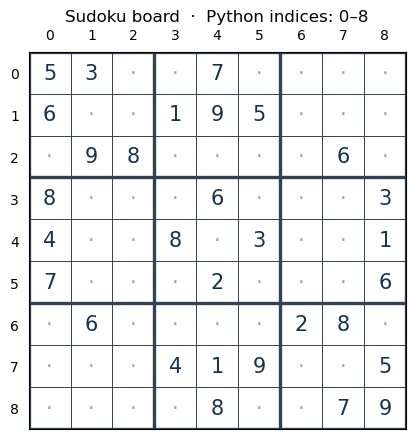

In [13]:
def show_board(values, selection=None, title="Sudoku board"):
    """Draw a 9x9 board; optional selection = (row_start, row_stop, col_start, col_stop)."""
    values = np.asarray(values)
    fig, ax = plt.subplots(figsize=(4.9, 4.9))
    ax.set_xlim(-0.5, 8.5)
    ax.set_ylim(8.5, -0.5)  # row 0 stays at the top
    ax.set_aspect("equal")

    if selection is not None:
        r0, r1, c0, c1 = selection
        ax.add_patch(Rectangle((c0 - 0.5, r0 - 0.5), c1 - c0, r1 - r0,
                               facecolor="#D7EAFE", edgecolor="#2563EB", linewidth=2))

    for row_index in range(9):
        for col_index in range(9):
            value = int(values[row_index, col_index])
            ax.text(col_index, row_index, str(value) if value else "·",
                    ha="center", va="center", fontsize=15,
                    color="#17324D" if value else "#9CA3AF")

    for line_index in range(10):
        coordinate = line_index - 0.5
        thickness = 2.4 if line_index % 3 == 0 else 0.7
        ax.axhline(coordinate, color="#334155", lw=thickness)
        ax.axvline(coordinate, color="#334155", lw=thickness)

    ax.set_xticks(range(9), [str(i) for i in range(9)])
    ax.set_yticks(range(9), [str(i) for i in range(9)])
    ax.xaxis.tick_top()
    ax.tick_params(length=0, labelsize=10, pad=7)
    ax.set_title(title + "  ·  Python indices: 0–8", fontsize=12, pad=22)
    plt.show()

show_board(board)

**Read the picture:** Row and column labels are **Python indices** (0–8). In a Sudoku game, people usually call these rows and columns **1–9**.



#### Break

## 5 · Find values in the grid

### Indexing: select one element

In a 2D NumPy array, write `board[row_index, column_index]`.

- Indices start at **0**; the top-left cell is `board[0, 0]`.
- The last cell is `board[8, 8]` or `board[-1, -1]`.
- A **negative index** counts backward from the end (`-1` means last).


board[0, 0] = 5
board[2, 1] = 9
board[-1, -1] = 9


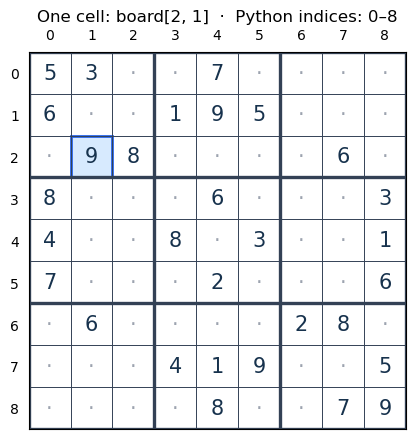

In [14]:
print("board[0, 0] =", board[0, 0])
print("board[2, 1] =", board[2, 1])
print("board[-1, -1] =", board[-1, -1])
show_board(board, selection=(2, 3, 1, 2), title="One cell: board[2, 1]")

### Rows and columns: the colon `:` means “all”

- `board[2, :]` → row with index **2**, across all columns.
- `board[:, 4]` → column with index **4**, across all rows.

Selecting one row or column gives a **1D array** with shape `(9,)`.

board[2, :] = [0 9 8 0 0 0 0 6 0]   shape: (9,)
board[:, 4] = [7 9 0 6 0 2 0 1 8]   shape: (9,)


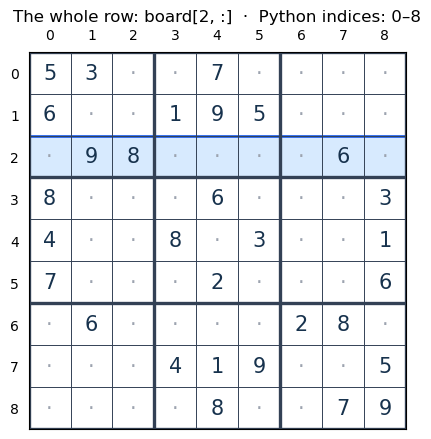

In [15]:
third_row = board[2, :]
fifth_column = board[:, 4]

print("board[2, :] =", third_row, "  shape:", third_row.shape)
print("board[:, 4] =", fifth_column, "  shape:", fifth_column.shape)
show_board(board, selection=(2, 3, 0, 9), title="The whole row: board[2, :]")

### Slicing: select a range

A slice uses `start:stop:step`:

- **start:** first index to include (default: beginning).
- **stop:** first index **not** included (default: end).
- **step:** how far to jump each time (default: `1`).

**Which values included `values[2:5]`?** it actually contains indices **2, 3, 4** — exactly 3 values.

Let's verify on a 1D array before slicing the Sudoku grid.

In [16]:
positions = np.arange(10)  # [0, 1, ..., 9]
print("positions:   ", positions)
print("[2:5]:       ", positions[2:5])
print("[:3]:        ", positions[:3])
print("[6:]:        ", positions[6:])
print("[1:9:2]:     ", positions[1:9:2])
print("[::2]:       ", positions[::2])

positions:    [0 1 2 3 4 5 6 7 8 9]
[2:5]:        [2 3 4]
[:3]:         [0 1 2]
[6:]:         [6 7 8 9]
[1:9:2]:      [1 3 5 7]
[::2]:        [0 2 4 6 8]


### A slice for each axis

In `board[rows, columns]`, we can independently choose **row indices** and **column indices**.

For the **center 3 × 3 box**:
- Rows **3, 4, 5** → `3:6`.
- Columns **3, 4, 5** → `3:6`.
- Therefore, use **`board[3:6, 3:6]`**.

**Whole board → highlighted selection → slice expression → extracted values.**

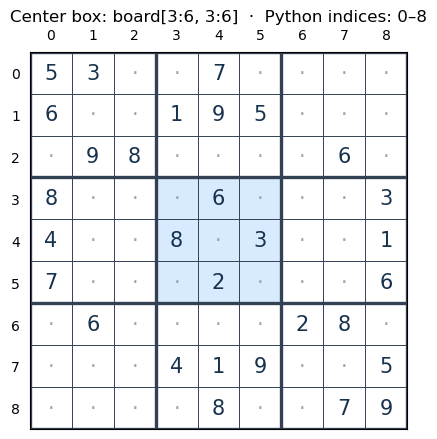

Extracted 3x3 box:
 [[0 6 0]
 [8 0 3]
 [0 2 0]]
Selected shape: (3, 3)


In [17]:
center_box = board[3:6, 3:6]
show_board(board, selection=(3, 6, 3, 6), title="Center box: board[3:6, 3:6]")
print("Extracted 3x3 box:\n", center_box)
print("Selected shape:", center_box.shape)

### Your turn · Choose a 3 × 3 box

1. Which slice selects the **top-left** box?
2. Which slice selects the **bottom-right** box?

**Predict before running the next cell.**

Top-left: board[0:3, 0:3]
 [[5 3 0]
 [6 0 0]
 [0 9 8]]


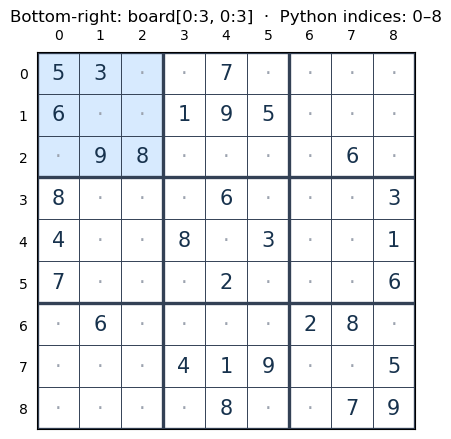


Bottom-right: board[6:9, 6:9]
 [[2 8 0]
 [0 0 5]
 [0 7 9]]


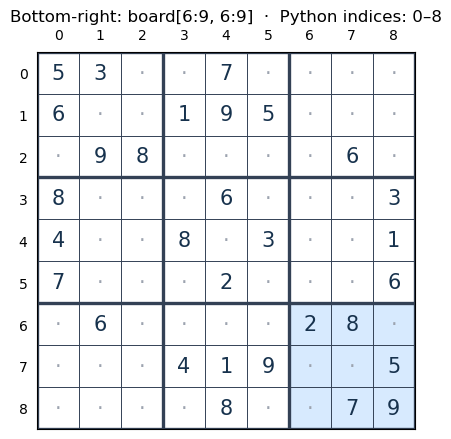

In [18]:
print("Top-left: board[0:3, 0:3]\n", board[0:3, 0:3])
show_board(board, selection=(0, 3, 0, 3), title="Bottom-right: board[0:3, 0:3]")
print("\nBottom-right: board[6:9, 6:9]\n", board[6:9, 6:9])
show_board(board, selection=(6, 9, 6, 9), title="Bottom-right: board[6:9, 6:9]")

**A useful detail:** `board[2, :]` gives shape `(9,)`, while `board[2:3, :]` keeps a row axis and gives shape `(1, 9)`.

We can also select every second row or column, for example `board[::2, ::2]`. This is still slicing — we simply change the **step**.

In [19]:
print("One row with integer index:", board[2, :].shape)
print("One-row slice:           ", board[2:3, :].shape)
print("Every second row/column:\n", board[::2, ::2])

One row with integer index: (9,)
One-row slice:            (1, 9)
Every second row/column:
 [[5 0 7 0 0]
 [0 8 0 0 0]
 [4 0 0 0 1]
 [0 0 0 2 0]
 [0 0 8 0 9]]


## 6 · Change and inspect arrays

### Assignment: filling an empty cell

Reading uses `board[0, 2]`; **writing** uses `board[0, 2] = 4`.

To preserve the original puzzle, first make a **copy**. We will change the copy only.

Before: 0
After:  4
Original is unchanged: 0


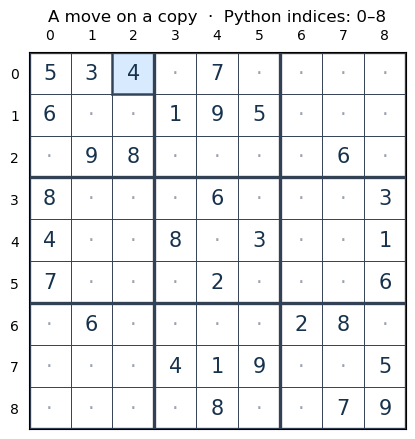

In [20]:
board_trial = board.copy()
print("Before:", board_trial[0, 2])
board_trial[0, 2] = 4
print("After: ", board_trial[0, 2])
print("Original is unchanged:", board[0, 2])
show_board(board_trial, selection=(0, 1, 2, 3), title="A move on a copy")

### Watch out: a slice is usually a **view**

A basic NumPy slice normally **shares values** with the array it came from.

- `region = board_trial[0:3, 0:3]` → a **view**; edits affect `board_trial`.
- `region = board_trial[0:3, 0:3].copy()` → independent **copy**.

Let's change one value and compare. Our original `board` remains safe.

In [21]:
board_trial = board.copy()
region_view = board_trial[0:3, 0:3]
region_view[0, 2] = 4                   # changes board_trial too

region_copy = board_trial[0:3, 0:3].copy()
region_copy[0, 2] = 0                  # changes only region_copy

print("trial board cell:", board_trial[0, 2])
print("view cell:       ", region_view[0, 2])
print("separate copy:  ", region_copy[0, 2])
print("original cell:  ", board[0, 2])

trial board cell: 4
view cell:        4
separate copy:   0
original cell:   0


### Ask the board a question: comparisons and masks

`board == 0` creates a **Boolean array** — one `True` or `False` per cell.

We can use such a **mask** to select values or count matching cells.

- `np.count_nonzero(mask)` → number of `True` entries.
- `np.unique(values)` → the different values present.
- `np.any(condition)` / `np.all(condition)` → whether at least one / every entry satisfies a condition.

In [22]:
empty_cells = board == 0
print("Empty-cell mask (top-left box):\n", empty_cells[0:3, 0:3])
print("Empty cells:", np.count_nonzero(empty_cells))
print("Filled cells:", np.count_nonzero(board))
print("Distinct values in center box:", np.unique(board[3:6, 3:6]))
print("Is 9 in row 3?", np.any(board[2, :] == 9))
print("Is row 1 complete?", np.all(board[0, :] != 0))
print("Nonzero digits in row 1:", board[0, :][board[0, :] != 0])

Empty-cell mask (top-left box):
 [[False False  True]
 [False  True  True]
 [ True False False]]
Empty cells: 51
Filled cells: 30
Distinct values in center box: [0 2 3 6 8]
Is 9 in row 3? True
Is row 1 complete? False
Nonzero digits in row 1: [5 3 7]


A mask can also **replace selected values**. For example, in a numerical report we may mark zero values with `-1`. (This is **not** a valid way to complete Sudoku.)

In [23]:
example_values = np.array([0, 12, 0, 21, 18])
print("Values greater than 15:", example_values[example_values > 15])
example_values[example_values == 0] = -1
print("Zeros replaced:       ", example_values)

Values greater than 15: [21 18]
Zeros replaced:        [-1 12 -1 21 18]


## 7 · Explore Sudoku with numerical operations

So far, we have used NumPy to **represent, select, and change** cells. Now let's ask questions about the **same board**.

**Remember the rules:** In a *completed* Sudoku, every row, column, and 3 × 3 box contains the digits **1–9 exactly once**. Their sum must therefore be **45** (`1 + 2 + ... + 9`).

- Our puzzle is **not yet complete**: `0` means an empty cell.
- Its row, column, and box sums will often be **less than 45**.
- **A sum of 45 alone does not prove a group is valid**. We also need to check digits and duplicates.

We will keep `board` unchanged and perform our experiments on a **copy**.

In [24]:
working_board = board.copy()
print("Same starting numbers?", np.array_equal(working_board, board))
print("Is the puzzle complete?", np.all(working_board != 0))
print("Empty cells:", np.count_nonzero(working_board == 0))
print("Target sum of a completed row, column, or box:", np.sum(np.arange(1, 10)))

Same starting numbers? True
Is the puzzle complete? False
Empty cells: 51
Target sum of a completed row, column, or box: 45


### 7.1 · Add the digits: `np.sum()` and `axis`

**Question:** What is the sum of the first row? How could we calculate **all nine row sums at once**?

- `np.sum(working_board[0, :])` → one selected row.
- `np.sum(working_board, axis=1)` → sum **across columns**, producing **one number per row**.
- `np.sum(working_board, axis=0)` → sum **down rows**, producing **one number per column**.
- `np.sum(working_board)` → sum **all 81 cells** into one number.

`axis` indicates the direction NumPy **reduces**, not the direction of the result.

In [25]:
first_row_sum = np.sum(working_board[0, :])
row_sums = np.sum(working_board, axis=1)
column_sums = np.sum(working_board, axis=0)

print("First row:", working_board[0, :], "→ sum:", first_row_sum)
print("Row sums (axis=1):   ", row_sums, "shape:", row_sums.shape)
print("Column sums (axis=0):", column_sums, "shape:", column_sums.shape)
print("Sum of all cells:    ", np.sum(working_board))
print("Rows already summing to 45:", np.count_nonzero(row_sums == 45))

First row: [5 3 0 0 7 0 0 0 0] → sum: 15
Row sums (axis=1):    [15 21 23 17 16 15 16 19 24] shape: (9,)
Column sums (axis=0): [30 18  8 13 33 17  2 21 24] shape: (9,)
Sum of all cells:     166
Rows already summing to 45: 0


### See both axes on the same board

The numbers **on the right** summarize each **row** (`axis=1`). The numbers **at the bottom** summarize each **column** (`axis=0`). These are *diagnostics*, not a proof that a Sudoku group is correct.

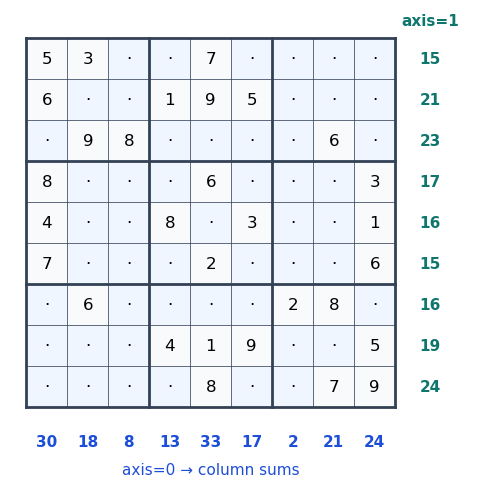

In [26]:
# Display helper: concentrate on the highlighted results, not the drawing code.
fig, ax = plt.subplots(figsize=(7.2, 6.2))
for r in range(9):
    for c in range(9):
        value = working_board[r, c]
        ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1,
                               facecolor="#F8FAFC" if value else "#EFF6FF",
                               edgecolor="#CBD5E1", linewidth=0.6))
        ax.text(c, r, str(value) if value else "·", ha="center", va="center", fontsize=12)
    ax.text(9.35, r, str(row_sums[r]), va="center", ha="center",
            color="#0F766E", fontweight="bold", fontsize=11)
for c in range(9):
    ax.text(c, 9.35, str(column_sums[c]), va="center", ha="center",
            color="#1D4ED8", fontweight="bold", fontsize=11)
for line in range(10):
    thickness = 2 if line % 3 == 0 else 0.5
    ax.plot([-0.5, 8.5], [line - 0.5, line - 0.5], color="#334155", lw=thickness)
    ax.plot([line - 0.5, line - 0.5], [-0.5, 8.5], color="#334155", lw=thickness)
ax.text(9.35, -0.8, "axis=1", color="#0F766E", ha="center", fontsize=11, fontweight="bold")
ax.text(4, 10.15, "axis=0 → column sums", color="#1D4ED8", ha="center", fontsize=11)
ax.set_xlim(-0.9, 10.3)
ax.set_ylim(10.45, -1.2)
ax.set_aspect("equal")
ax.axis("off")
plt.show()

### 7.2 · Explore a column: minimum, maximum, mean, median

Consider **column 5** in the game (Python index `4`).

- `np.min()` / `np.max()` → smallest / largest value.
- `np.mean()` → arithmetic average; `np.median()` → middle value when sorted.
- `np.count_nonzero()` → how many cells already contain a digit.

**Important:** If we include the `0`s, the minimum and average describe our **stored grid**, not just the **filled digits**. A Boolean mask lets us separate them.

In [27]:
column = working_board[:, 4]
filled_digits = column[column != 0]

print("Column at index 4:", column)
print("Including empty cells → min:", np.min(column), "max:", np.max(column),
      "mean:", round(np.mean(column), 2))
print("Only filled digits   → min:", np.min(filled_digits), "max:", np.max(filled_digits))
print("Only filled digits   → mean:", round(np.mean(filled_digits), 2),
      "median:", np.median(filled_digits))
print("Filled cell count:", np.count_nonzero(column))
print("Distinct filled digits:", np.unique(filled_digits))

Column at index 4: [7 9 0 6 0 2 0 1 8]
Including empty cells → min: 0 max: 9 mean: 3.67
Only filled digits   → min: 1 max: 9
Only filled digits   → mean: 5.5 median: 6.5
Filled cell count: 6
Distinct filled digits: [1 2 6 7 8 9]


### 7.3 · Compare two 3 × 3 boxes

Let's take the **top-left** and **bottom-right** boxes. Each one is a `(3, 3)` array, so NumPy can calculate with their matching positions.

- `+` and `-`: element-wise addition and subtraction.
- `*`: element-wise multiplication (**not** matrix multiplication).
- `/`: element-wise division; dividing by a number makes a numerical *analysis*, not a Sudoku move.

**These calculations do not enforce Sudoku rules.** We use them to understand how NumPy operates on two arrays of the same shape.

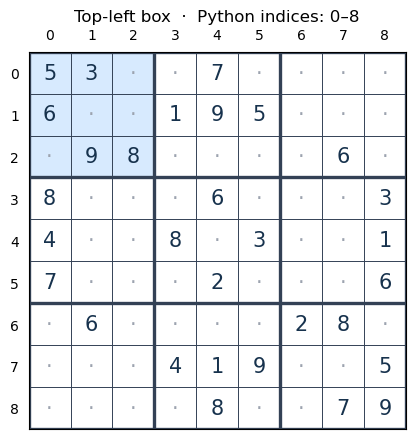

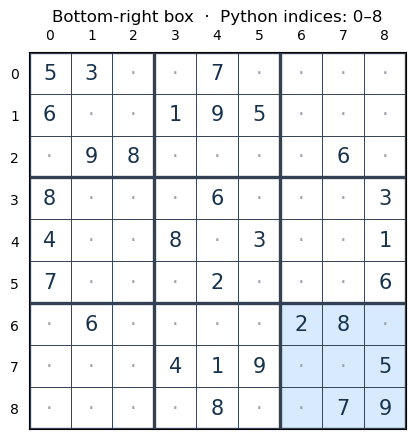

Top-left (shape): (3, 3) 
 [[5 3 0]
 [6 0 0]
 [0 9 8]]
Bottom-right:    
 [[2 8 0]
 [0 0 5]
 [0 7 9]]
Top-left box sum: 31
Bottom-right box sum: 31


In [28]:
top_left_box = working_board[0:3, 0:3].copy()
bottom_right_box = working_board[6:9, 6:9].copy()

show_board(working_board, selection=(0, 3, 0, 3), title="Top-left box")
show_board(working_board, selection=(6, 9, 6, 9), title="Bottom-right box")

print("Top-left (shape):", top_left_box.shape, "\n", top_left_box)
print("Bottom-right:    \n", bottom_right_box)
print("Top-left box sum:", np.sum(top_left_box))
print("Bottom-right box sum:", np.sum(bottom_right_box))

In [29]:
print("A + B (each matching cell):\n", top_left_box + bottom_right_box)
print("A - B:\n", top_left_box - bottom_right_box)
print("A * B (element-wise):\n", top_left_box * bottom_right_box)
print("A / 2:\n", top_left_box / 2)
print("Original top-left box still unchanged:",
      np.array_equal(top_left_box, board[0:3, 0:3]))

A + B (each matching cell):
 [[ 7 11  0]
 [ 6  0  5]
 [ 0 16 17]]
A - B:
 [[ 3 -5  0]
 [ 6  0 -5]
 [ 0  2 -1]]
A * B (element-wise):
 [[10 24  0]
 [ 0  0  0]
 [ 0 63 72]]
A / 2:
 [[2.5 1.5 0. ]
 [3.  0.  0. ]
 [0.  4.5 4. ]]
Original top-left box still unchanged: True


### A closer look · Dot and cross products (short extension)

NumPy also supports *geometric* products. They are useful in other areas of computing, **not for deciding whether a Sudoku move is legal**.

- **Dot product:** Flatten two 3 × 3 boxes into two 9-element vectors. Multiply matching entries and add them. `np.dot(a, b)` returns **one number**.
- **Cross product:** Uses **three-element vectors**. `np.cross(A, B)` on our two boxes computes one cross product **for each pair of corresponding 3-element rows**. The output is another 3 × 3 array.
- **Matrix multiplication** (`A @ B`) is different again; we do not need it for Sudoku.

**Predict:** Why does the dot product return a scalar, while the row-wise cross products return three vectors?

In [30]:
vector_a = top_left_box.reshape(9)
vector_b = bottom_right_box.reshape(9)

print("Flattened box shapes:", vector_a.shape, vector_b.shape)
print("Dot product (one number):", np.dot(vector_a, vector_b))
print("Cross product of corresponding 3-number rows:\n",
      np.cross(top_left_box, bottom_right_box))
print("Matrix product A @ B (different operation):\n",
      top_left_box @ bottom_right_box)

Flattened box shapes: (9,) (9,)
Dot product (one number): 169
Cross product of corresponding 3-number rows:
 [[  0   0  34]
 [  0 -30   0]
 [ 25   0   0]]
Matrix product A @ B (different operation):
 [[ 10  40  15]
 [ 12  48   0]
 [  0  56 117]]


### 7.4 · A Sudoku rule is more than a sum

For a **finished** group, `45` is necessary, but **not sufficient**.

**Question:** Both example rows below add to `45`. Are they both valid Sudoku rows?

Look for duplicates with `np.unique()` and count the distinct digits.

In [31]:
correct_row = np.arange(1, 10)
wrong_row = np.array([2, 2, 3, 3, 5, 6, 7, 8, 9])

for name, numbers in [("Correct", correct_row), ("Incorrect", wrong_row)]:
    print(name, "row:", numbers)
    print("  sum:", np.sum(numbers), "| distinct digits:", np.unique(numbers).size,
          "| no duplicates:", np.unique(numbers).size == numbers.size)

# A group can have no duplicate *filled* digits even when it still has zeros.
first_row_filled = working_board[0, :][working_board[0, :] != 0]
print("Our incomplete first row (filled values only):", first_row_filled)
print("No duplicates so far:", np.unique(first_row_filled).size == first_row_filled.size)

Correct row: [1 2 3 4 5 6 7 8 9]
  sum: 45 | distinct digits: 9 | no duplicates: True
Incorrect row: [2 2 3 3 5 6 7 8 9]
  sum: 45 | distinct digits: 7 | no duplicates: False
Our incomplete first row (filled values only): [5 3 7]
No duplicates so far: True


### Your turn · Connect the operations

Before running, predict the answers:

1. How many **empty** cells are inside the bottom-right box?
2. Does the first row contain the digit `9`?
3. Are **all** the digits in the top-left box between `1` and `9`? (Remember the empty cells.)
4. If a puzzle were complete, why would checking **only** the total of `45` still be unsafe?

In [32]:
print("Empty cells in bottom-right box:", np.count_nonzero(bottom_right_box == 0))
print("Is 9 in the first row?", np.any(working_board[0, :] == 9))
print("All top-left entries are in 1..9?",
      np.all((top_left_box >= 1) & (top_left_box <= 9)))
print("What we need for Sudoku: valid digits AND no duplicates in rows, columns, boxes.")

Empty cells in bottom-right box: 4
Is 9 in the first row? False
All top-left entries are in 1..9? False
What we need for Sudoku: valid digits AND no duplicates in rows, columns, boxes.


## 8 · Assignment 01 — Validate and solve a Sudoku puzzle

**Your challenge for the coming week:** Use **NumPy indexing, slicing, Boolean conditions, and `np.any()`** to enforce Sudoku's rules.

You will **not** implement a complete solving algorithm. We provide the randomized starting board **and** a small brute-force solver with **backtracking**. **Your task is to write one function:** `is_valid_move()`.

**What counts as a legal move?** A candidate must:

1. Be an integer between **1 and 9**, placed in a **currently empty** cell.
2. **Not already appear** in that row.
3. **Not already appear** in that column.
4. **Not already appear** in the cell's 3 × 3 box.

If any check fails, return `False`. Otherwise return `True`. **Never alter the original puzzle inside this function.**

### Provided setup · A different, valid puzzle

A completely random arrangement of numbers would usually **break the rules**. Instead, the following helper randomizes **digit names and orientation** of our known-valid puzzle. That preserves a correct starting configuration. Change the seed for another version.

*The generator code is provided; you do not need to understand its randomization details for this assignment.*

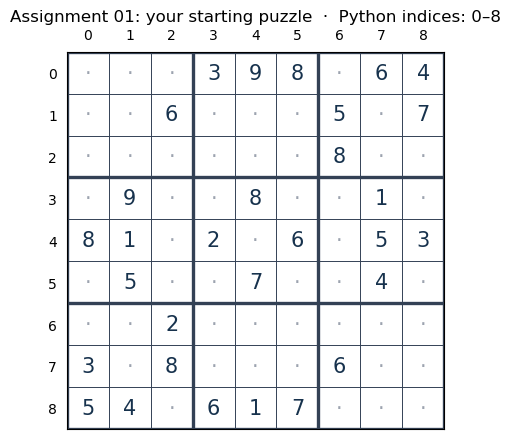

Original class board unchanged: True
Clues: 30 | Empty cells: 51


In [33]:
def make_random_sudoku(base_board, seed=2026):
    """Return a randomized but still legal Sudoku puzzle; 0 means empty."""
    rng = np.random.default_rng(seed)
    digit_map = np.concatenate(([0], rng.permutation(np.arange(1, 10))))
    puzzle = digit_map[base_board]                  # keep empty cells at 0
    puzzle = np.rot90(puzzle, k=int(rng.integers(4)))  # rotate the entire board
    return puzzle.copy()

assignment_puzzle = make_random_sudoku(board, seed=2026)
show_board(assignment_puzzle, title="Assignment 01: your starting puzzle")
print("Original class board unchanged:", np.array_equal(board, np.array(sudoku_rows)))
print("Clues:", np.count_nonzero(assignment_puzzle),
      "| Empty cells:", np.count_nonzero(assignment_puzzle == 0))

### Your code · Write the Sudoku correctness check

**Complete the single function below.** The comments tell you where to add your checks. You already know how to select a row (`grid[row, :]`), a column (`grid[:, col]`), and a 3 × 3 box (`grid[r0:r0+3, c0:c0+3]`).

**Hint:** The top-left index of the relevant box is `(row // 3) * 3, (col // 3) * 3`. Try `np.any(selected_values == digit)` to detect a duplicate.

The current `return False` is only a **placeholder**. Replace it after implementing the checks.

In [34]:
def is_valid_move(grid, row, col, digit):
    """Return True only if digit can be placed at this currently empty position."""
    # TODO 1: Reject an already filled cell or a digit outside 1..9

    if (
        not isinstance(digit, (int, np.integer))
        or not (1 <= digit <= 9)
        or grid[row, col] != 0
    ):
        return False

    # TODO 2: Reject a duplicate in the selected ROW.
    if np.any(grid[row, :] == digit):
        return False

    # TODO 3: Reject a duplicate in the selected COLUMN.
    if np.any(grid[:, col] == digit):
        return False

    # TODO 4: Find the 3x3 BOX, then reject a duplicate in that box.
    start_row = (row // 3) * 3
    start_col = (col // 3) * 3
    box = grid[start_row : start_row + 3, start_col : start_col + 3]

    if np.any(box == digit):
        return False

    # TODO 5: Return True if all checks pass.
    return True  # Placeholder; replace with your solution.

### Provided code · Try candidates, and backtrack when necessary

This solver is **given**. You only need to understand its overall behavior:

- Find an empty cell (`0`). Try candidate digits `1` to `9`.
- Call **your** `is_valid_move()` to reject moves that violate the rules.
- When a legal choice leads to a dead end, **undo it** and try another candidate (*backtracking*).
- Finish when there are no empty cells. The original puzzle is kept safe because we work on a copy.

**You do not need to write recursion or backtracking yourself.**

In [35]:
def solve_with_backtracking(puzzle):
    attempt = puzzle.copy()

    def search():
        empty_positions = np.argwhere(attempt == 0)
        if len(empty_positions) == 0:
            return True  # Every cell has been filled.

        row, col = empty_positions[0]
        for digit in range(1, 10):
            if is_valid_move(attempt, row, col, digit):
                attempt[row, col] = digit
                if search():
                    return True
                attempt[row, col] = 0  # Undo a choice that led to a dead end.
        return False

    return attempt if search() else None

print("Solver provided. First complete is_valid_move() above, then run the checks below.")

Solver provided. First complete is_valid_move() above, then run the checks below.


### How to check your work

Use the **original class puzzle** for predictable tests. Each expected result below targets a particular rule:

| Test | Why? | Expected |
|---|---|---|
| `is_valid_move(board, 0, 2, 4)` | Legal candidate | `True` |
| `is_valid_move(board, 0, 2, 5)` | `5` already in row | `False` |
| `is_valid_move(board, 0, 3, 8)` | `8` already in column | `False` |
| `is_valid_move(board, 0, 2, 6)` | `6` already in 3 × 3 box | `False` |
| `is_valid_move(board, 0, 0, 4)` | Cell already filled | `False` |

Once your function works, **uncomment** the lines below. The full solver should return a completed board. Check that each row, column, and box contains `1–9` once. The `assert`s test your function; they are intentionally commented out until you implement it.

Solved? True


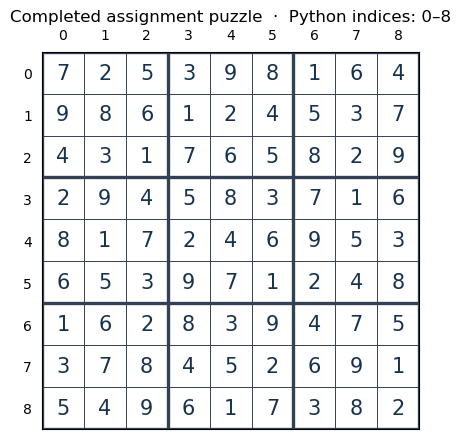

Each row sums to 45: True
Each column sums to 45: True


In [36]:
# After finishing is_valid_move(), uncomment these lines:
assert is_valid_move(board, 0, 2, 4)
assert not is_valid_move(board, 0, 2, 5)  # row conflict
assert not is_valid_move(board, 0, 3, 8)  # column conflict
assert not is_valid_move(board, 0, 2, 6)  # box conflict
assert not is_valid_move(board, 0, 0, 4)  # occupied cell
assert not is_valid_move(board, 0, 2, 0)  # invalid digit

solved = solve_with_backtracking(assignment_puzzle)
print("Solved?", solved is not None)
if solved is not None:
    show_board(solved, title="Completed assignment puzzle")
    print("Each row sums to 45:", np.all(np.sum(solved, axis=1) == 45))
    print("Each column sums to 45:", np.all(np.sum(solved, axis=0) == 45))
    # Remember: the sums are only a quick check, not proof of correctness.

### What to submit

Submit **THIS notebook** containing your implementation of `is_valid_move()`

**Success:** The solver produces a complete Sudoku without changing the given clues, and each row, column, and box has digits `1–9` exactly once.

**Optional extension:** Write `is_valid_completed_board(grid)` to check *all* rows, columns, and boxes after solving.

**Deadline**: Saturday 24/10/2026 Mid-day (11:59 AM) on Google Classroom.

## 9 · Wrap-up and what comes next

**Today we learned that:**

1. Sudoku is a **2D numerical array**: its shape and slices let us select individual cells, rows, columns, and boxes.
2. NumPy supports **arithmetic, comparisons, masks, and summaries** over the same board. `axis=0` gives one result per **column**; `axis=1` gives one per **row** for a 2D array.

**L03 — Exploring and Manipulating Data with Pandas:** We will transfer these data skills from a numerical grid to tables with **named columns** and different types of observations.

---
### References and acknowledgement

- NumPy documentation: [Absolute beginners](https://numpy.org/doc/stable/user/absolute_beginners.html) · [Quickstart](https://numpy.org/doc/stable/user/quickstart.html) · [Indexing and slicing](https://numpy.org/doc/stable/user/basics.indexing.html).
- Teaching reference: Prof. Antonio Liotta's materials on Python objects, data types and datasets, NumPy arrays, two-dimensional arrays, and introductory NumPy exercises.